Simulate the field on [−20, 20] with ∆x = 0.02, an explicit Euler step ∆t = 0.02, FFT convolution
with zero padding, and H replaced by a steep sigmoid 1/(1 + e−100(u−κ)
). For κ = 0.3 start from u(x, 0) =
W(x+a0)−W(x−a0) with a0 = a− ±0.02 and a0 = a+ ±0.05, and plot the half-width of the active region against
time. Which return, which run away and which die? For κ = 0.1, 0.3, 0.45 start the wide bump 0.05 too wide and fit
the relaxation rate of |a(t) − a+| on a log scale; compare with λe(a+).

k = 0.3: a-=0.2031, a+=1.6941, U(0)= 0.34890191618901545 0.9796576178561596
a0 = 0.1831: die
a0 = 0.2231: -> 1.6942
a0 = 1.6441: -> 1.6942
a0 = 1.7441: -> 1.6942


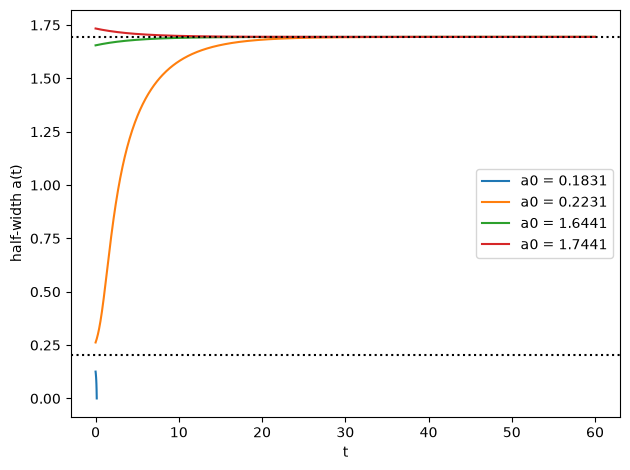

k = 0.1: fitted rate = -0.0867, lambda_e(a+) = -0.0902
k = 0.3: fitted rate = -0.2076, lambda_e(a+) = -0.2083
k = 0.45: fitted rate = -0.1979, lambda_e(a+) = -0.1951


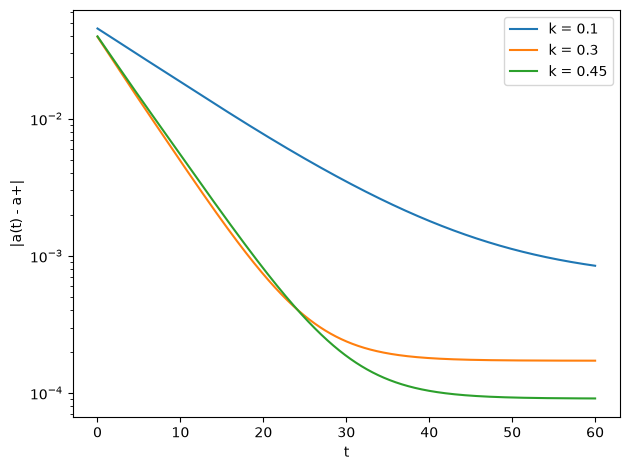

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

# parameters
dx = dt = 0.02
x = np.arange(-20, 20 + dx / 2, dx)
w = lambda r: 2 * np.exp(-np.abs(r)) - np.exp(-np.abs(r)/2)
W = lambda r: np.sign(r) * (2 * np.exp(-np.abs(r) / 2) - 2 * np.exp(-np.abs(r)))
center = w(x)
H = lambda u, k: 1 / (1 + np.exp(-100 * np.clip(u - k, -50, 50) / 1))

def a_pm(k):
    r = np.sqrt(1 - 2 * k)
    return -np.log((1 + r) / 2), -np.log((1 - r) / 2)

def lam_e(a, k):
    s = np.exp(-a)
    w2 = s - k
    return 2 * w2 / (1 - w2)

def halfwidth(u, k):
    idx = np.where(u[x >= 0] >= k)[0]
    if len(idx) == 0: 
        return 0.0
    i = idx[-1] + np.searchsorted(x, 0)
    if i >= len(x) - 1:
        return x[-1]
    return x[i] + dx * (u[i] - k) / (u[i] - u[i + 1])

def run(a0, k, T, stop = 15):
    u = W(x + a0) - W(x - a0)
    n = int(T / dt)
    t = np.arange(n + 1) * dt
    a = np.zeros(n + 1)
    a[0] = halfwidth(u, k)

    for j in range(1, n + 1):
        f = fftconvolve(H(u, k), center, mode = "same") * dx
        u = u + dt * (-u + f)
        a[j] = halfwidth(u, k)
        if a[j] == 0 or a[j] > stop:
            return t[:j + 1], a[:j + 1]
    return t, a

# k = 0.3
k = 0.3
am, ap = a_pm(k)
print(f"k = 0.3: a-={am:.4f}, a+={ap:.4f}, U(0)=", 2 * W(am), 2 * W(ap))
plt.figure()
for a0 in [am - 0.02, am + 0.02, ap - 0.05, ap + 0.05]:
    t, a = run(a0, k, 60)
    end = "die" if a[-1] == 0 else ("runs away" if a[-1] > 10 else f"-> {a[-1]:.4f}")
    print(f"a0 = {a0:.4f}: {end}")
    plt.plot(t, a, label = f"a0 = {a0:.4f}")
plt.axhline(am, ls = ":", c = "k")
plt.axhline(ap, ls = ":", c = "k")
plt.xlabel("t")
plt.ylabel("half-width a(t)")
plt.legend()
plt.tight_layout()
plt.show()

# bump started too wide
plt.figure()
for k in [0.1, 0.3, 0.45]:
    ap = a_pm(k)[1]
    t, a = run(ap + 0.05, k, 60)
    err = np.abs(a - ap)
    m = np.argmax(err < 4e-3) or len(t)
    sl = slice(int(0.1 * m), m)
    rate = np.polyfit(t[sl], np.log(err[sl]), 1)[0]
    print(f"k = {k}: fitted rate = {rate:.4f}, lambda_e(a+) = {lam_e(ap, k):.4f}")
    plt.semilogy(t, err, label = f"k = {k}")
plt.xlabel("t")
plt.ylabel("|a(t) - a+|")
plt.legend()
plt.tight_layout()
plt.show()